## Análise de Capacidade e Distribuição da Procura (Dataset Small)
**Autor:** Fábio Ferreira (29365)

### 1. Carregamento e Preparação dos Dados
Carregamos os ficheiros CSV necessários para analisar a relação entre o peso das encomendas e a capacidade da frota (`order_items`, `orders`, `products`, `producers`, `delivery_locations` e `vehicles`). Cruzamos os itens com os respetivos produtos e encomendas e extraímos o dia e a hora das janelas temporais para avaliar a evolução da procura ao longo do tempo.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# Altera para "docs/data_tiny/" se quiseres correr para o tiny
DATA = "docs/data_small_30_31oct2026/"
DATE_COLS = ["availability_start", "availability_end", "delivery_start", "delivery_end"]

# 1. Carregar apenas os CSVs necessários para Capacidade e Procura
items      = pd.read_csv(DATA + "order_items.csv", parse_dates=DATE_COLS)
orders     = pd.read_csv(DATA + "orders.csv", parse_dates=["order_datetime"])
products   = pd.read_csv(DATA + "products.csv")
producers  = pd.read_csv(DATA + "producers.csv")
deliv_locs = pd.read_csv(DATA + "delivery_locations.csv")
vehicles   = pd.read_csv(DATA + "vehicles.csv")

# 2. Cruzar tabelas (Merge)
df = items.merge(products[["product_id", "producer_id", "name", "category", "unit", "unit_weight_kg"]], on="product_id", how="left")
df = df.merge(orders[["order_id", "customer_id", "delivery_location_id", "status"]], on="order_id", how="left")

# Garantir que weight_kg existe (necessário caso corras no dataset tiny)
if "weight_kg" not in df.columns:
    df["weight_kg"] = df["quantity"] * df["unit_weight_kg"]

# 3. Extrair variáveis temporais (Dia e Hora)
df["dia_recolha"]  = df["availability_start"].dt.date
df["dia_entrega"]  = df["delivery_start"].dt.date
df["hora_recolha"] = df["availability_start"].dt.hour
df["hora_entrega"] = df["delivery_start"].dt.hour

display(df.head())

,order_item_id,order_id,product_id,quantity,weight_kg,availability_start,availability_end,delivery_start,delivery_end,producer_id,...,category,unit,unit_weight_kg,customer_id,delivery_location_id,status,dia_recolha,dia_entrega,hora_recolha,hora_entrega
0,1,1,12,12.0,12.0,2026-10-30 07:45:00,2026-10-30 10:45:00,2026-10-30 12:30:00,2026-10-30 14:30:00,3,...,vegetable,kg,1.0,9,5,confirmed,2026-10-30,2026-10-30,7,12
1,2,1,30,7.4,7.4,2026-10-30 08:15:00,2026-10-30 10:15:00,2026-10-30 12:30:00,2026-10-30 14:30:00,6,...,fruit,kg,1.0,9,5,confirmed,2026-10-30,2026-10-30,8,12
2,3,2,26,9.9,9.9,2026-10-30 08:15:00,2026-10-30 10:15:00,2026-10-30 13:30:00,2026-10-30 16:45:00,6,...,fruit,kg,1.0,4,4,confirmed,2026-10-30,2026-10-30,8,13
3,4,2,18,17.9,17.9,2026-10-30 07:00:00,2026-10-30 09:30:00,2026-10-30 13:30:00,2026-10-30 16:45:00,4,...,vegetable,kg,1.0,4,4,confirmed,2026-10-30,2026-10-30,7,13
4,5,2,7,2.9,2.9,2026-10-30 08:45:00,2026-10-30 12:30:00,2026-10-30 13:30:00,2026-10-30 16:45:00,2,...,fruit,kg,1.0,4,4,confirmed,2026-10-30,2026-10-30,8,13


### 2. Peso a Transportar vs. Capacidade dos Veículos
Comparamos a procura total e diária com a capacidade máxima da frota. Como as regras operacionais do conjunto *small* exigem que todos os produtos passem pelo centro de recolha (`producer > warehouse > delivery_location`), o esforço de transporte divide-se em duas operações distintas: recolhas nos produtores e entregas nos clientes.

Peso Total (2 dias): 580.0 kg | Capacidade Total da Frota: 550.0 kg


,vehicle_id,capacity_kg,refrigerated
0,1,250.0,1
1,2,300.0,0


,itens_recolha,peso_recolha_kg,itens_entrega,peso_entrega_kg,% frota (recolha),% frota (entrega)
dia_recolha,,,,,,
2026-10-30,46,338.7,26,182.6,61.6,33.2
2026-10-31,34,241.3,54,397.4,43.9,72.3


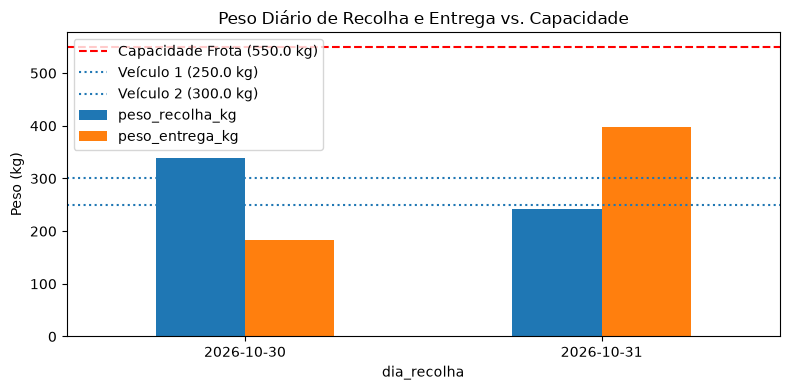

In [7]:
cap_total = vehicles["capacity_kg"].sum()
peso_total = df["weight_kg"].sum()

print(f"Peso Total (2 dias): {peso_total:.1f} kg | Capacidade Total da Frota: {cap_total:.1f} kg")
display(vehicles[["vehicle_id", "capacity_kg", "refrigerated"]])

# Agrupar por dia de Recolha e por dia de Entrega
recolha_dia = df.groupby("dia_recolha").agg(itens_recolha=("order_item_id", "count"), peso_recolha_kg=("weight_kg", "sum"))
entrega_dia = df.groupby("dia_entrega").agg(itens_entrega=("order_item_id", "count"), peso_entrega_kg=("weight_kg", "sum"))

resumo_dias = recolha_dia.join(entrega_dia)

# Calcular % de ocupação da frota total por dia
resumo_dias["% frota (recolha)"] = (100 * resumo_dias["peso_recolha_kg"] / cap_total).round(1)
resumo_dias["% frota (entrega)"] = (100 * resumo_dias["peso_entrega_kg"] / cap_total).round(1)
display(resumo_dias)

# Gráfico comparativo
ax = resumo_dias[["peso_recolha_kg", "peso_entrega_kg"]].plot.bar(figsize=(8, 4), rot=0)
ax.axhline(cap_total, color="red", linestyle="--", label=f"Capacidade Frota ({cap_total} kg)")
for vid, cap in vehicles[["vehicle_id", "capacity_kg"]].itertuples(index=False):
    ax.axhline(cap, linestyle=":", label=f"Veículo {vid} ({cap} kg)")
ax.set_ylabel("Peso (kg)")
ax.set_title("Peso Diário de Recolha e Entrega vs. Capacidade")
ax.legend()
plt.tight_layout()
plt.show()

**Conclusões sobre Peso vs. Capacidade:**
* **Gargalo Global:** O peso total a transportar nos dois dias é de **580.0 kg** (distribuídos por 80 itens), ultrapassando a capacidade combinada dos dois veículos (**550.0 kg**). A capacidade passa a ser uma restrição ativa no problema.
* **Análise Diária (Recolhas vs. Entregas):**
  * **30/10/2026:** São recolhidos **338.7 kg** (46 itens), mas apenas são entregues **182.6 kg** (26 itens). Os restantes 20 itens (156.1 kg) pernoitam no centro de recolha (que suporta até 5000 kg).
  * **31/10/2026:** São recolhidos **241.3 kg** (34 itens), mas o volume de entregas sobe para **397.4 kg** (54 itens), juntando os itens recolhidos no próprio dia aos que ficaram armazenados da véspera.
* **Impacto na Modelação:** Nenhum dia isolado excede os 550 kg totais da frota num único sentido, mas o volume de recolhas no dia 30 (338.7 kg) e o de entregas no dia 31 (397.4 kg) superam a capacidade de um veículo isolado, exigindo a utilização coordenada dos dois veículos ou múltiplas viagens com retorno ao armazém.

### 3. Análise de Peso por Encomenda e por Item
Verificamos se existe alguma encomenda completa (`order_id`) ou item individual (`order_item_id`) cujo peso ultrapasse a capacidade de um único veículo, o que exigiria a divisão de uma mesma encomenda.

In [8]:
por_encomenda = df.groupby("order_id").agg(
    itens=("order_item_id", "count"),
    peso_total_kg=("weight_kg", "sum"),
    dia_recolha=("dia_recolha", "first")
).sort_values("peso_total_kg", ascending=False)

print(f"Encomenda mais pesada: {por_encomenda['peso_total_kg'].max():.1f} kg (Order ID: {por_encomenda.index[0]})")
print(f"Item individual mais pesado: {df['weight_kg'].max():.1f} kg (Item ID: {df.loc[df['weight_kg'].idxmax(), 'order_item_id']})")
print(f"Menor capacidade de um veículo: {vehicles['capacity_kg'].min():.1f} kg")

display(por_encomenda.head(5))

Encomenda mais pesada: 38.4 kg (Order ID: 18)
Item individual mais pesado: 21.8 kg (Item ID: 77)
Menor capacidade de um veículo: 250.0 kg


,itens,peso_total_kg,dia_recolha
order_id,,,
18,6,38.4,2026-10-30
25,4,37.7,2026-10-30
22,4,36.1,2026-10-31
9,4,33.6,2026-10-30
14,3,31.9,2026-10-30


**Conclusões sobre Encomendas Individuais:**
* A encomenda mais pesada (`order_id = 18`, composta por 6 itens) pesa **38.4 kg**, e o item individual mais pesado (`order_item_id = 77`, Cereja) pesa **21.8 kg**.
* Todas as encomendas e itens individuais cabem folgadamente num único veículo. O estrangulamento de capacidade resulta exclusivamente da acumulação de vários pedidos na mesma viagem.

### 4. Necessidade de Veículo Refrigerado
Inspecionamos a frota e as categorias de produtos (`products.csv`) para determinar se existem alimentos perecíveis que imponham uma restrição unária de atribuição exclusiva a veículos refrigerados (`refrigerated = 1`).

In [9]:
print("Veículos e refrigeração:")
display(vehicles[["vehicle_id", "capacity_kg", "refrigerated"]])

print("\nCategorias e produtos existentes no dataset:")
resumo_prod = df.groupby(["category", "name", "unit"]).agg(
    pedidos=("order_item_id", "count"),
    peso_total_kg=("weight_kg", "sum")
).reset_index()
display(resumo_prod)

Veículos e refrigeração:


,vehicle_id,capacity_kg,refrigerated
0,1,250.0,1
1,2,300.0,0



Categorias e produtos existentes no dataset:


,category,name,unit,pedidos,peso_total_kg
0,fruit,Castanha,kg,4,34.6
1,fruit,Cereja,kg,10,82.1
2,fruit,Kiwi,kg,1,7.9
3,fruit,Laranja,kg,2,12.1
4,fruit,Maca,kg,2,25.0
5,fruit,Pera,kg,7,38.6
6,other,Ovos,crate,1,9.0
7,vegetable,Batata,kg,14,104.7
8,vegetable,Cebola,kg,5,34.0
9,vegetable,Cenoura,kg,4,36.0


## Conclusões sobre Refrigeração:
* A procura divide-se em três categorias: `vegetable` (370.7 kg), `fruit` (200.3 kg) e `other` (9.0 kg, correspondente a Mel e Ovos).
* Nem o catálogo de produtos nem o ficheiro `rules.csv` especificam requisitos de temperatura ou obrigatoriedade de frio. Na modelação base, todos os produtos podem ser atribuídos a qualquer veículo sem restrição de refrigeração.

### 5. Distribuição da Procura por Produtor, Local e Hora
Analisamos como o peso total (580 kg) se distribui geograficamente pelos produtores e locais de entrega, bem como temporalmente pelas horas de abertura das janelas de recolha (`availability_start`) e de entrega (`delivery_start`).

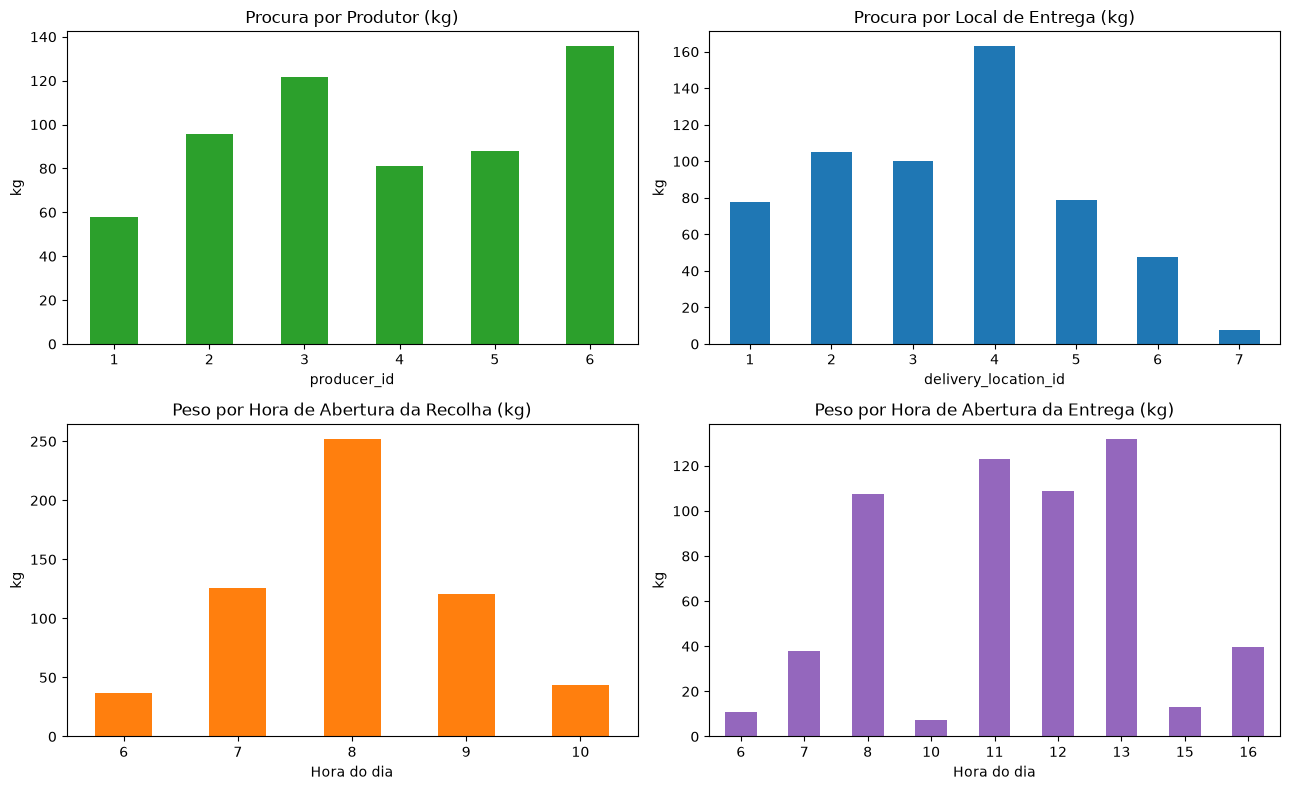

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(13, 8))

# 1. Peso por Produtor
df.groupby("producer_id")["weight_kg"].sum().plot.bar(
    ax=axs[0, 0], color="tab:green", rot=0, title="Procura por Produtor (kg)"
)
axs[0, 0].set_ylabel("kg")

# 2. Peso por Local de Entrega
df.groupby("delivery_location_id")["weight_kg"].sum().plot.bar(
    ax=axs[0, 1], color="tab:blue", rot=0, title="Procura por Local de Entrega (kg)"
)
axs[0, 1].set_ylabel("kg")

# 3. Peso por Hora de Início de Recolha
df.groupby("hora_recolha")["weight_kg"].sum().plot.bar(
    ax=axs[1, 0], color="tab:orange", rot=0, title="Peso por Hora de Abertura da Recolha (kg)"
)
axs[1, 0].set_xlabel("Hora do dia"); axs[1, 0].set_ylabel("kg")

# 4. Peso por Hora de Início de Entrega
df.groupby("hora_entrega")["weight_kg"].sum().plot.bar(
    ax=axs[1, 1], color="tab:purple", rot=0, title="Peso por Hora de Abertura da Entrega (kg)"
)
axs[1, 1].set_xlabel("Hora do dia"); axs[1, 1].set_ylabel("kg")

plt.tight_layout()
plt.show()

**Conclusões sobre a Distribuição da Procura e Preparação para o Modelo:**
* **Concentração nos Produtores:** O maior volume de carga encontra-se no **Produtor 6 (135.7 kg)** e no **Produtor 3 (121.8 kg)**, que juntos representam 44% de todo o peso a recolher. O Produtor 1 tem a menor procura (57.9 kg).
* **Concentração nas Entregas:** O **Local de Entrega 4** é o principal ponto crítico da distribuição, absorvendo **163.0 kg** (23 itens), seguido dos Locais 2 (105.0 kg) e 3 (100.3 kg). O Local 7 recebe apenas 7.5 kg.
* **Padrão Temporal:** As aberturas de recolha ocorrem todas de manhã entre as **06h e as 10h**, com um forte pico às **08h (252.2 kg)**. As aberturas de entrega concentram-se sobretudo entre as **11h e as 13h (364.1 kg acumulados)**.
* **Decisão para a Modelação e CSP:** A separação temporal clara entre o pico de recolhas (manhã) e o pico de entregas (início da tarde), aliada à regra de passagem obrigatória pelo armazém, favorece a divisão das rotas em viagens matinais de recolha (produtores → armazém) e viagens de distribuição (armazém → clientes), controlando a capacidade acumulada em cada viagem através de uma restrição de limite de carga (`capacity_kg`) por rota atribuída.